# 50-image end-to-end POC (Proof of Concept)

In [2]:
from pathlib import Path
import random
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image

In [3]:
dataset_root = Path.cwd().parent / "data" / "raw" / "bdd100k"

train_dir = dataset_root / "train" / "images"
val_dir = dataset_root / "val" / "images"
test_dir = dataset_root / "test"

poc_dir = Path.cwd().parent / "data" / "poc"

random.seed(42)

In [4]:
annotation_file = next(
    (dataset_root / "train" / "annotations").glob("*.json")
)

with open(annotation_file, "r") as f:
    train_annotations = json.load(f)

### Hypothesis: Larger vehicle bounding boxes are more likely to contain visible licence plates.

#### We can calculate the largest vehicle bounding box and the number of vehicles present in each image.

In [5]:
vehicle_categories = {"car", "truck", "bus", "motor"}

records = []

for record in train_annotations:

    vehicle_areas = []

    for obj in record.get("labels", []):

        if obj["category"] not in vehicle_categories:
            continue

        if "box2d" not in obj:
            continue

        box = obj["box2d"]

        width = box["x2"] - box["x1"]
        height = box["y2"] - box["y1"]

        if width > 0 and height > 0:
            vehicle_areas.append(width * height)

    records.append({
        "image_id": record["name"],
        "vehicle_count": len(vehicle_areas),
        "max_vehicle_area": max(vehicle_areas, default=0),
        "timeofday": record["attributes"].get("timeofday"),
        "weather": record["attributes"].get("weather"),
        "scene": record["attributes"].get("scene")
    })

df = pd.DataFrame(records)

df.head()

,image_id,vehicle_count,max_vehicle_area,timeofday,weather,scene
0,0000f77c-6257be58.jpg,2,88514.384906,daytime,clear,city street
1,0000f77c-62c2a288.jpg,0,0.000000,dawn/dusk,clear,highway
2,0000f77c-cb820c98.jpg,7,34049.453081,dawn/dusk,clear,residential
3,0001542f-5ce3cf52.jpg,10,2539.360018,night,clear,city street
4,0001542f-7c670be8.jpg,3,2136.416194,night,clear,highway


In [6]:
df["max_vehicle_area"].describe(
    percentiles=[0.25, 0.5, 0.75, 0.9, 0.95]
)

count     69863.000000
mean      61699.449055
std       67290.945540
min           0.000000
25%       12909.054819
50%       38928.130603
75%       89080.862924
90%      147714.958270
95%      194453.555988
max      828772.182217
Name: max_vehicle_area, dtype: float64

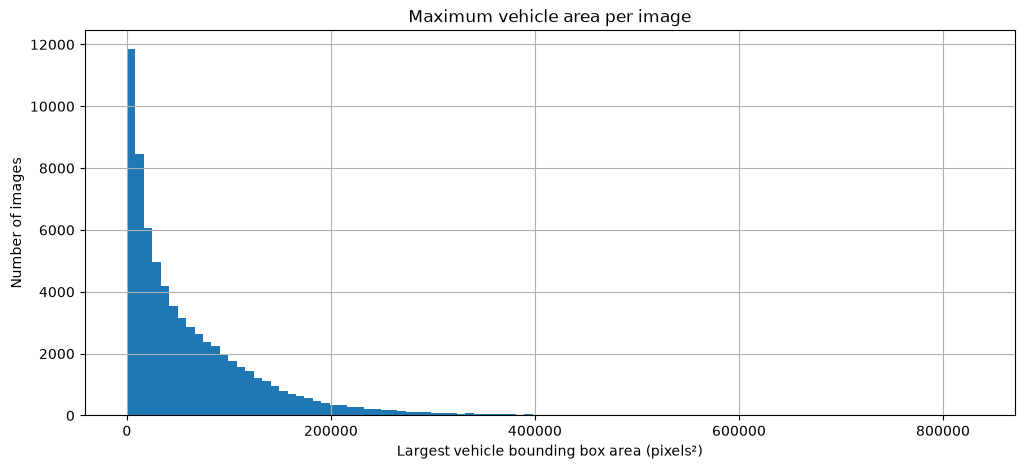

In [7]:
df.loc[
    df["max_vehicle_area"] > 0,
    "max_vehicle_area"
].hist(bins=100, figsize=(12, 5))

plt.xlabel("Largest vehicle bounding box area (pixels²)")
plt.ylabel("Number of images")
plt.title("Maximum vehicle area per image")
plt.show()

In [24]:
# This helps us determine what constitutes a small, medium or large vehicle in our actual dataset rather than choosing arbitrary thresholds.

In [8]:
candidate_groups = [
    df[df["max_vehicle_area"].between(30_000, 200_000)]
        .sample(300, random_state=42),

    df[df["max_vehicle_area"].between(1_000, 29_999)]
        .sample(100, random_state=42),

    df[df["max_vehicle_area"] > 200_000]
        .sample(50, random_state=42),

    df[df["vehicle_count"] == 0]
        .sample(50, random_state=42)
]

candidates = (
    pd.concat(candidate_groups)
    .drop_duplicates(subset="image_id")
    .sample(frac=1, random_state=42)
    .reset_index(drop=True)
)

print("Candidate images:", len(candidates))

Candidate images: 500


In [26]:
%pip install ipywidgets

Note: you may need to restart the kernel to use updated packages.


In [9]:
import ipywidgets as widgets
from IPython.display import display

targets = {
    "Clear": 15,
    "Multiple": 5,
    "Small": 5,
    "Difficult": 7,
    "Negative": 3
}

current_idx = 0

selected = {}
rejected = set()

image_widget = widgets.Image(
    format="jpeg",
    width=1100
)

status = widgets.HTML()
progress = widgets.HTML()

prev_btn = widgets.Button(description="Previous")
next_btn = widgets.Button(description="Next")

reject_btn = widgets.Button(
    description="Reject",
    button_style="danger"
)

undo_btn = widgets.Button(description="Unassign")

In [10]:
category_buttons = {
    category: widgets.Button(
        description=category,
        button_style="success",
        layout=widgets.Layout(width="160px")
    )
    for category in targets
}

In [11]:
def show_current_image():

    row = candidates.iloc[current_idx]
    filename = row["image_id"]

    image_widget.value = (train_dir / filename).read_bytes()

    counts = {
        category: list(selected.values()).count(category)
        for category in targets
    }

    decision = selected.get(
        filename,
        "Rejected" if filename in rejected else "Unreviewed"
    )

    status.value = (
        f"<b>Image:</b> {current_idx + 1}/{len(candidates)} | "
        f"<b>Selected:</b> {len(selected)}/35 | "
        f"<b>Rejected:</b> {len(rejected)} | "
        f"<b>Status:</b> {decision}<br>"
        f"<b>Filename:</b> {filename}<br>"
        f"<b>Time:</b> {row['timeofday']} | "
        f"<b>Weather:</b> {row['weather']} | "
        f"<b>Vehicles:</b> {row['vehicle_count']} | "
        f"<b>Max vehicle area:</b> {row['max_vehicle_area']:.0f}"
    )

    progress.value = " &nbsp; | &nbsp; ".join(
        f"<b>{category}:</b> {counts[category]}/{target}"
        for category, target in targets.items()
    )

    for category, button in category_buttons.items():

        count = counts[category]
        target = targets[category]

        button.description = f"{category} ({count}/{target})"

        button.disabled = (
            count >= target
            and selected.get(filename) != category
        )

    prev_btn.disabled = current_idx == 0
    next_btn.disabled = current_idx == len(candidates) - 1

In [14]:
def next_image(button=None):
    global current_idx

    current_idx = min(
        current_idx + 1,
        len(candidates) - 1
    )

    show_current_image()


def previous_image(button=None):
    global current_idx

    current_idx = max(current_idx - 1, 0)

    show_current_image()

def assign_category(category):

    filename = candidates.iloc[current_idx]["image_id"]

    count = list(selected.values()).count(category)

    if count >= targets[category] and selected.get(filename) != category:
        return

    selected[filename] = category
    rejected.discard(filename)

    save_selection()
    next_image()
def reject_image(button=None):

    filename = candidates.iloc[current_idx]["image_id"]

    selected.pop(filename, None)
    rejected.add(filename)

    save_selection()
    next_image()


def unassign_image(button=None):

    filename = candidates.iloc[current_idx]["image_id"]

    selected.pop(filename, None)
    rejected.discard(filename)

    save_selection()
    show_current_image()

poc_dir.mkdir(parents=True, exist_ok=True)

def save_selection():

    # Save selected images and their categories
    selection_df = candidates[
        candidates["image_id"].isin(selected)
    ].copy()

    selection_df["sampling_category"] = (
        selection_df["image_id"].map(selected)
    )

    selection_df.to_csv(
        poc_dir / "train_selection.csv",
        index=False
    )

    # Save review progress
    review_df = candidates[["image_id"]].copy()

    review_df["decision"] = (
        review_df["image_id"]
        .map(selected)
        .astype("string")
    )

    review_df.loc[
        review_df["image_id"].isin(rejected),
        "decision"
    ] = "Rejected"

    review_df["decision"] = (
        review_df["decision"].fillna("Unreviewed")
    )

    review_df.to_csv(
        poc_dir / "review_progress.csv",
        index=False
    )

In [15]:
prev_btn.on_click(previous_image)
next_btn.on_click(next_image)
reject_btn.on_click(reject_image)
undo_btn.on_click(unassign_image)

for category, button in category_buttons.items():

    button.on_click(
        lambda b, cat=category: assign_category(cat)
    )

display(
    widgets.VBox([
        status,
        progress,

        widgets.HBox(
            list(category_buttons.values())
        ),

        widgets.HBox([
            prev_btn,
            next_btn,
            reject_btn,
            undo_btn
        ]),

        image_widget
    ])
)

save_selection()
show_current_image()

In [16]:
# Our widget automatically saved the selections to data/poc/train_selection.csv. We no longer depend on the notebook's in-memory state.

In [17]:
selected_df = pd.read_csv(poc_dir / "train_selection.csv")

print("Total selected:", len(selected_df))

selected_df["sampling_category"].value_counts()

Total selected: 35


sampling_category
Clear        15
Difficult     7
Small         5
Multiple      5
Negative      3
Name: count, dtype: int64

In [18]:
assert len(selected_df) == 35
assert selected_df["image_id"].is_unique

### Select validation and test images

In [19]:
val_images = sorted(val_dir.glob("*.jpg"))
test_images = sorted(test_dir.glob("*.jpg"))

rng = random.Random(42)

val_selected = rng.sample(val_images, 5)
test_selected = rng.sample(test_images, 10)

In [20]:
train_manifest = pd.DataFrame({
    "image_id": selected_df["image_id"],
    "split": "train",
    "sampling_category": selected_df["sampling_category"],
    "source_path": selected_df["image_id"].apply(
        lambda name: str(train_dir / name)
    )
})

val_manifest = pd.DataFrame([
    {
        "image_id": path.name,
        "split": "val",
        "sampling_category": "Random",
        "source_path": str(path)
    }
    for path in val_selected
])

test_manifest = pd.DataFrame([
    {
        "image_id": path.name,
        "split": "test",
        "sampling_category": "Random",
        "source_path": str(path)
    }
    for path in test_selected
])

In [22]:
manifest = pd.concat(
    [train_manifest, val_manifest, test_manifest],
    ignore_index=True
)

manifest.head()

,image_id,split,sampling_category,source_path
0,ab12975c-abce86fe.jpg,train,Negative,c:\Users\aarish.tickoo\workspace\traffic-pii-m...
1,92b12a2d-68c584f8.jpg,train,Negative,c:\Users\aarish.tickoo\workspace\traffic-pii-m...
2,1337f4dd-d87d60e9.jpg,train,Negative,c:\Users\aarish.tickoo\workspace\traffic-pii-m...
3,195fd017-7ee9a071.jpg,train,Difficult,c:\Users\aarish.tickoo\workspace\traffic-pii-m...
4,6e631f87-7d308e09.jpg,train,Difficult,c:\Users\aarish.tickoo\workspace\traffic-pii-m...


In [23]:
print(manifest["split"].value_counts())

assert len(manifest) == 50
assert manifest["image_id"].is_unique

split
train    35
test     10
val       5
Name: count, dtype: int64


In [24]:
manifest.to_csv(
    poc_dir / "dataset_manifest.csv",
    index=False
)

### Copy the actual images

In [25]:
import shutil

for split in ["train", "val", "test"]:

    (poc_dir / "images" / split).mkdir(
        parents=True, exist_ok=True
    )

    (poc_dir / "labels" / split).mkdir(
        parents=True, exist_ok=True
    )

In [26]:
for row in manifest.itertuples(index=False):

    source = Path(row.source_path)

    destination = (
        poc_dir / "images" / row.split / row.image_id
    )

    shutil.copy2(source, destination)

In [28]:
# verify the final datset split 
for split in ["train", "val", "test"]:

    image_count = len(
        list((poc_dir / "images" / split).glob("*.jpg"))
    )

    print(f"{split}: {image_count} images")

train: 35 images
val: 5 images
test: 10 images


### YOLO dataset preparation and annotation verification

In [ ]:
# Contents of data.yaml
yolo_dir = poc_dir / "yolo_dataset"

print((yolo_dir / "data.yaml").read_text())

Test: Test.txt
Train: Train.txt
Validation: Validation.txt
names:
  0: license_plate
path: .



In [ ]:
# Number of images and labels in each split.
for folder in ["images", "labels"]:
    print(f"\n{folder.upper()}")

    for split_dir in (yolo_dir / folder).iterdir():
        if split_dir.is_dir():
            print(split_dir.name, len(list(split_dir.iterdir())))


IMAGES
Test 10
Train 35
Validation 5

LABELS
Test 5
Train 25
Validation 2


In [31]:
label_files = sorted(
    (yolo_dir / "labels").rglob("*.txt")
)

print("Total label files:", len(label_files))

Total label files: 32


In [32]:
label_path = next(
    path for path in label_files
    if path.read_text().strip()
)

print(label_path.name)
print(label_path.read_text())

d22dc344-46571c2f.txt
0 0.535156 0.845486 0.087234 0.063667



In [33]:
def yolo_to_xyxy(box, image_width, image_height):

    cx, cy, bw, bh = box

    cx *= image_width
    cy *= image_height

    bw *= image_width
    bh *= image_height

    x1 = cx - bw / 2
    y1 = cy - bh / 2

    x2 = cx + bw / 2
    y2 = cy + bh / 2

    return x1, y1, x2, y2

### Visualize our manually annotated bounding boxes

In [34]:
import matplotlib.patches as patches

image_path = next(
    (yolo_dir / "images").rglob(
        label_path.stem + ".jpg"
    )
)

image = Image.open(image_path).convert("RGB")

w, h = image.size

annotations = np.loadtxt(
    label_path,
    ndmin=2
)

print(annotations)

[[0.       0.535156 0.845486 0.087234 0.063667]]


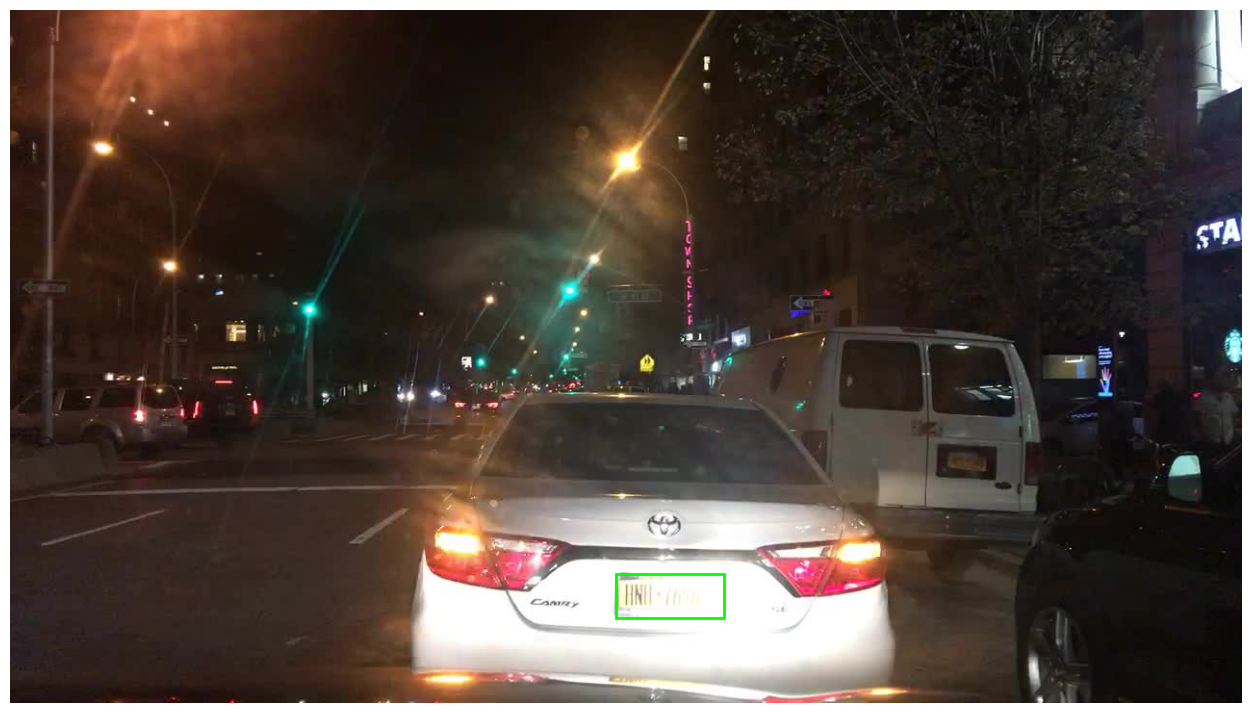

In [35]:
fig, ax = plt.subplots(figsize=(16, 9))

ax.imshow(image)

for annotation in annotations:

    class_id, *box = annotation

    x1, y1, x2, y2 = yolo_to_xyxy(box, w, h)

    rectangle = patches.Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        edgecolor="lime",
        facecolor="none",
        linewidth=2
    )

    ax.add_patch(rectangle)

ax.axis("off")
plt.show()

### Count annotated licence plates

In [36]:
records = []

for path in label_files:

    lines = path.read_text().strip().splitlines()

    records.append({
        "image_id": path.stem,
        "split": path.parent.name,
        "plate_count": len(lines)
    })

annotation_stats = pd.DataFrame(records)

annotation_stats.head()

,image_id,split,plate_count
0,d22dc344-46571c2f,Test,1
1,d2f3e8c3-c04896c8,Test,1
2,d6087157-fc728703,Test,2
3,dccfcce5-ad496380,Test,1
4,f85bbdf5-4a8e3a62,Test,2


In [37]:
annotation_stats.groupby("split").agg(
    label_files=("image_id", "count"),
    total_plates=("plate_count", "sum"),
    average_plates=("plate_count", "mean"),
    max_plates=("plate_count", "max")
)

,label_files,total_plates,average_plates,max_plates
split,,,,
Test,5,7,1.40,2
Train,25,48,1.92,4
Validation,2,3,1.50,2


In [38]:
annotation_stats["plate_count"].sum()

np.int64(58)